# FireWatch AI

We analyze satellite thermal detections in Australia during 2024. We use PySpark to process the data, K-Means to group locations, and Random Forest to predict whether a grid cell will have a detection in a given month.

## 1. Imports and setup
Open the FireWatch-AI folder in VS Code and use the `.venv311` kernel. This notebook reads the original project files and does not overwrite them.

In [1]:
import os
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve,
                             roc_auc_score, brier_score_loss)

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'dashboard' / 'app.py').is_file()), None)
if root is None:
    raise FileNotFoundError('Open the FireWatch-AI folder in VS Code first.')

data = root / 'data' / 'processed'
analytics = data / 'analytics'
models = root / 'models'
raw_path = root / 'data' / 'raw' / 'fire_archive_SV-C2_842285.csv'
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
plt.rcParams['figure.figsize'] = (8, 4)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
print('Project:', root)
print('Python:', sys.executable)

Project: c:\Users\Dell\Documents\FireWatch-AI
Python: c:\Users\Dell\Documents\FireWatch-AI\.venv311\Scripts\python.exe


In [2]:
# Use the same Python environment for the Spark workers.
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
os.environ['SPARK_LOCAL_IP'] = '127.0.0.1'
os.environ['SPARK_LOCAL_HOSTNAME'] = 'localhost'
if Path(r'C:\hadoop\bin\winutils.exe').is_file():
    os.environ['HADOOP_HOME'] = r'C:\hadoop'
    os.environ['PATH'] = r'C:\hadoop\bin' + os.pathsep + os.environ['PATH']

spark = None
try:
    from pyspark.sql import SparkSession, functions as F
    spark = (SparkSession.builder.master('local[2]')
             .appName('FireWatch')
             .config('spark.sql.shuffle.partitions', '4')
             .getOrCreate())
    spark.sparkContext.setLogLevel('ERROR')
    print('Spark version:', spark.version)
except Exception as e:
    print('Spark could not start:', e)
    print('Spark cells will be skipped. Saved results can still be displayed.')

Spark version: 4.0.1


## 2. Dataset
Source: [NASA FIRMS](https://firms.modaps.eosdis.nasa.gov/download/), VIIRS S-NPP, Australia, January–December 2024.

Each row is a satellite thermal detection, not necessarily a separate wildfire. FRP (Fire Radiative Power) is measured in MW.

In [3]:
if raw_path.is_file():
    raw = pd.read_csv(raw_path)
    print('Raw shape:', raw.shape)
    print('CSV size (MiB):', round(raw_path.stat().st_size / 1024**2, 2))
    display(raw.head())
    display(raw['type'].value_counts().sort_index().rename('records').to_frame())
    raw_rows = len(raw)
else:
    raw = None
    raw_rows = 979867
    print('Original CSV not found. Raw row count is from our previous run:', raw_rows)

clean = pd.read_parquet(data / 'firewatch_cleaned_file.parquet')
print('Cleaned shape:', clean.shape)
display(clean.head())

Raw shape: (979867, 15)
CSV size (MiB): 76.85


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,-30.70723,148.38664,339.52,0.44,0.46,2024-01-01,325,SNPP,SNPP,n,2,304.50,7.70,D,0
1,-28.21993,151.02919,344.59,0.46,0.39,2024-01-01,326,SNPP,SNPP,n,2,286.59,9.26,D,0
2,-28.11098,150.92123,330.17,0.46,0.39,2024-01-01,326,SNPP,SNPP,l,2,277.41,5.92,D,0
3,-28.22596,151.01068,340.77,0.46,0.39,2024-01-01,326,SNPP,SNPP,l,2,280.75,6.36,D,0
4,-28.22300,151.03441,352.65,0.46,0.39,2024-01-01,326,SNPP,SNPP,n,2,287.01,6.32,D,0


,records
type,
0,968740
2,10327
3,800


Cleaned shape: (968740, 19)


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,year,month,day_of_year,frp_category
0,-30.70723,148.38664,339.52,0.44,0.46,2024-01-01,325,SNPP,SNPP,n,2,304.50,7.70,D,0,2024,1,1,Low
1,-28.21993,151.02919,344.59,0.46,0.39,2024-01-01,326,SNPP,SNPP,n,2,286.59,9.26,D,0,2024,1,1,Low
2,-28.11098,150.92123,330.17,0.46,0.39,2024-01-01,326,SNPP,SNPP,l,2,277.41,5.92,D,0,2024,1,1,Low
3,-28.22596,151.01068,340.77,0.46,0.39,2024-01-01,326,SNPP,SNPP,l,2,280.75,6.36,D,0,2024,1,1,Low
4,-28.22300,151.03441,352.65,0.46,0.39,2024-01-01,326,SNPP,SNPP,n,2,287.01,6.32,D,0,2024,1,1,Low


## 3. Data cleaning
We kept type 0 (vegetation-fire candidates), checked missing values, duplicates and invalid coordinates/FRP, then added year, month, day of year and FRP category.

The full cleaning script is `src/03_preprocessing.py`. The next cells show the main operations and check its saved output.

In [4]:
if raw is not None:
    print('Missing values in raw data:')
    display(raw.isna().sum().rename('missing').to_frame())
    print('Duplicate raw rows:', raw.duplicated().sum())
    if spark is not None:
        try:
            # A short example of the original Spark filtering.
            raw_spark = spark.read.option('header', True).option('inferSchema', True).csv(str(raw_path))
            selected = (raw_spark.filter(F.col('type') == 0)
                        .dropna(subset=['latitude','longitude','frp'])
                        .filter(F.col('latitude').between(-90, 90))
                        .filter(F.col('longitude').between(-180, 180))
                        .filter(F.col('frp') >= 0))
            selected.select('latitude','longitude','frp','type').show(5)
        except Exception as e:
            print('Spark raw-data example failed:', e)

print('Missing values after cleaning:', clean.isna().sum().sum())
print('Duplicate cleaned rows:', clean.duplicated().sum())
print('Negative FRP:', (clean['frp'] < 0).sum())
print('Date range:', clean['acq_date'].min(), 'to', clean['acq_date'].max())

Missing values in raw data:


,missing
latitude,0
longitude,0
brightness,0
scan,0
track,0
acq_date,0
acq_time,0
satellite,0
instrument,0
confidence,0


Duplicate raw rows: 0
+---------+---------+----+----+
| latitude|longitude| frp|type|
+---------+---------+----+----+
|-30.70723|148.38664| 7.7|   0|
|-28.21993|151.02919|9.26|   0|
|-28.11098|150.92123|5.92|   0|
|-28.22596|151.01068|6.36|   0|
|  -28.223|151.03441|6.32|   0|
+---------+---------+----+----+
only showing top 5 rows
Missing values after cleaning: 0
Duplicate cleaned rows: 0
Negative FRP: 0
Date range: 2024-01-01 to 2024-12-31


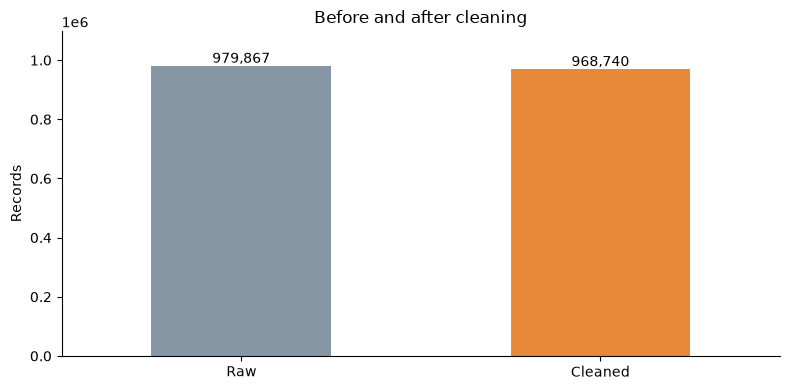

,acq_date,year,month,day_of_year,frp,frp_category
0,2024-01-01,2024,1,1,7.70,Low
1,2024-01-01,2024,1,1,9.26,Low
2,2024-01-01,2024,1,1,5.92,Low
3,2024-01-01,2024,1,1,6.36,Low
4,2024-01-01,2024,1,1,6.32,Low


In [5]:
counts = pd.Series({'Raw': raw_rows, 'Cleaned': len(clean)})
ax = counts.plot.bar(rot=0, color=['#8796a5','#e88939'], title='Before and after cleaning')
ax.set_ylabel('Records')
for i, value in enumerate(counts):
    ax.text(i, value, f'{value:,}', ha='center', va='bottom')
ax.set_ylim(0, counts.max() * 1.12)
plt.tight_layout()
plt.show()

display(clean[['acq_date','year','month','day_of_year','frp','frp_category']].head())

## 4. Spark DataFrames
Filtering selects rows, and aggregation summarizes them. Here we use the full cleaned dataset, not just a sample.

In [6]:
if spark is not None:
    try:
        df = spark.read.parquet(str(data / 'firewatch_cleaned_file.parquet'))
        df.printSchema()
        high_frp = df.filter(F.col('frp') >= 50)
        print('High FRP records:', high_frp.count())
        df.groupBy('month').agg(F.count('*').alias('detections'),
                               F.round(F.avg('frp'), 2).alias('avg_frp')).orderBy('month').show(12)
    except Exception as e:
        print('Spark DataFrame operations failed:', e)
else:
    print('Spark not available. See the saved analysis below.')

root
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- brightness: double (nullable = true)
 |-- scan: double (nullable = true)
 |-- track: double (nullable = true)
 |-- acq_date: date (nullable = true)
 |-- acq_time: integer (nullable = true)
 |-- satellite: string (nullable = true)
 |-- instrument: string (nullable = true)
 |-- confidence: string (nullable = true)
 |-- version: integer (nullable = true)
 |-- bright_t31: double (nullable = true)
 |-- frp: double (nullable = true)
 |-- daynight: string (nullable = true)
 |-- type: integer (nullable = true)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- day_of_year: integer (nullable = true)
 |-- frp_category: string (nullable = true)

High FRP records: 30347
+-----+----------+-------+
|month|detections|avg_frp|
+-----+----------+-------+
|    1|     40776|  14.35|
|    2|     15156|   16.9|
|    3|     20808|  12.75|
|    4|     94692|   9.61|
|    5|     95005|   8.3

### Spark SQL
We use SQL to calculate monthly counts and average FRP.

In [7]:
if spark is not None:
    try:
        df.createOrReplaceTempView('detections')
        spark.sql("""
            SELECT month, COUNT(*) AS detections, ROUND(AVG(frp), 2) AS avg_frp
            FROM detections
            GROUP BY month
            ORDER BY month
        """).show(12)
    except Exception as e:
        print('Spark SQL failed:', e)

+-----+----------+-------+
|month|detections|avg_frp|
+-----+----------+-------+
|    1|     40776|  14.35|
|    2|     15156|   16.9|
|    3|     20808|  12.75|
|    4|     94692|   9.61|
|    5|     95005|   8.39|
|    6|     66210|   8.45|
|    7|     54928|    8.0|
|    8|     75761|   9.18|
|    9|     99608|   9.11|
|   10|    198374|  12.89|
|   11|    145797|  11.89|
|   12|     61625|  11.59|
+-----+----------+-------+



### Geographic grid and join
We use `floor` on latitude and longitude to make 1° × 1° grid cells. A left join attaches a region ID to each detection. The lookup table is made from our own coordinates, not another dataset.

In [8]:
if spark is not None:
    try:
        grid_df = (df.withColumn('lat_grid', F.floor('latitude').cast('int'))
                     .withColumn('lon_grid', F.floor('longitude').cast('int')))
        regions = (grid_df.select('lat_grid', 'lon_grid').distinct()
                   .withColumn('region_id', F.concat_ws('_', 'lat_grid', 'lon_grid')))
        joined = grid_df.join(regions, ['lat_grid', 'lon_grid'], 'left')
        print('Regions:', regions.count())
        print('Joined rows:', joined.count())
        print('Missing region IDs:', joined.filter(F.col('region_id').isNull()).count())
        joined.select('lat_grid','lon_grid','region_id').show(5)
    except Exception as e:
        print('Spark join failed:', e)

Regions: 702
Joined rows: 968740
Missing region IDs: 0
+--------+--------+---------+
|lat_grid|lon_grid|region_id|
+--------+--------+---------+
|     -31|     148|  -31_148|
|     -29|     151|  -29_151|
|     -29|     150|  -29_150|
|     -29|     151|  -29_151|
|     -29|     151|  -29_151|
+--------+--------+---------+
only showing top 5 rows


## 5. Exploratory data analysis
The charts below use the actual summaries exported by our Spark scripts.

,month,total_detections,avg_frp,max_frp,total_frp,month_name
0,1,40776,14.35,716.80,585273.28,Jan
1,2,15156,16.90,1232.79,256164.64,Feb
2,3,20808,12.75,380.72,265225.44,Mar
3,4,94692,9.61,881.00,910007.21,Apr
4,5,95005,8.39,406.92,796878.91,May
5,6,66210,8.45,297.65,559541.96,Jun
6,7,54928,8.00,306.61,439639.04,Jul
7,8,75761,9.18,462.85,695143.99,Aug
8,9,99608,9.11,446.05,907489.40,Sep
9,10,198374,12.89,716.21,2557597.31,Oct


Total detections: 968740


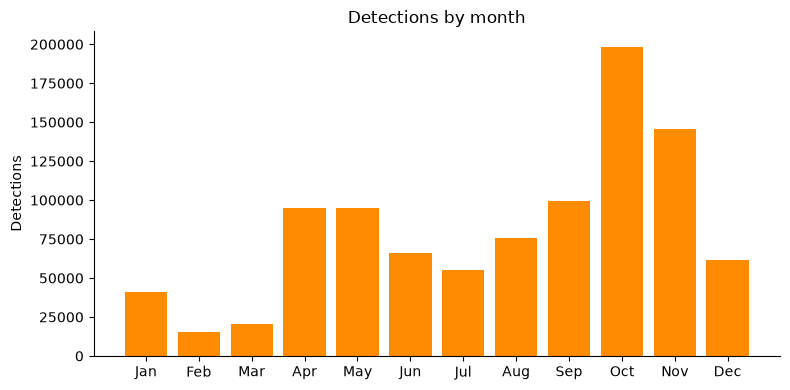

Peak month: Oct - 198374 detections


In [9]:
monthly = pd.read_parquet(analytics / 'monthly_statistics.parquet').sort_values('month')
monthly['month_name'] = monthly['month'].astype(int).map(dict(enumerate(months, 1)))
display(monthly)
print('Total detections:', monthly['total_detections'].sum())

plt.bar(monthly['month_name'], monthly['total_detections'], color='darkorange')
plt.title('Detections by month')
plt.ylabel('Detections')
plt.tight_layout()
plt.show()
peak = monthly.loc[monthly['total_detections'].idxmax()]
print('Peak month:', peak['month_name'], '-', int(peak['total_detections']), 'detections')

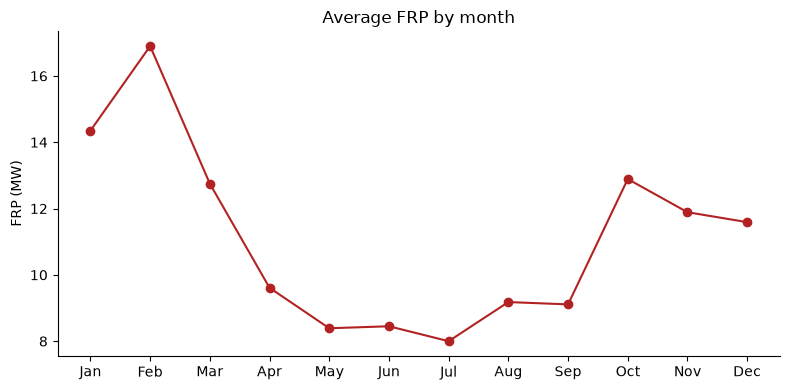

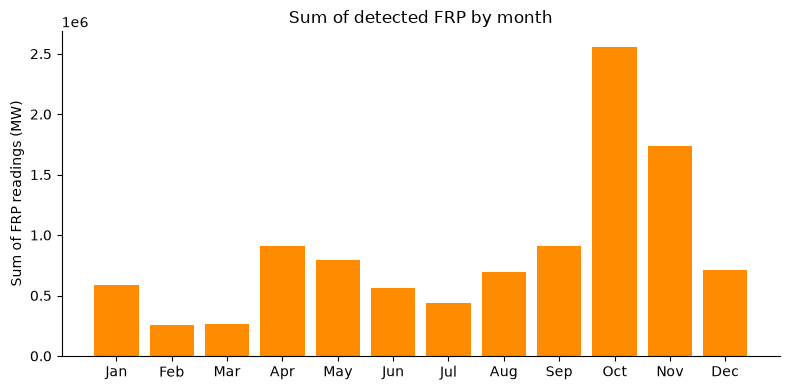

In [10]:
plt.plot(monthly['month_name'], monthly['avg_frp'], marker='o', color='firebrick')
plt.title('Average FRP by month')
plt.ylabel('FRP (MW)')
plt.tight_layout()
plt.show()

if 'total_frp' in monthly.columns:
    plt.bar(monthly['month_name'], monthly['total_frp'], color='darkorange')
    plt.title('Sum of detected FRP by month')
    plt.ylabel('Sum of FRP readings (MW)')
    plt.tight_layout()
    plt.show()

### FRP categories
Our own categories: Low (below 10 MW), Moderate (10 to below 50 MW), High (50 MW or above). These are not official wildfire severity classes.

,detections
frp_category,
Low,711402
Moderate,226991
High,30347


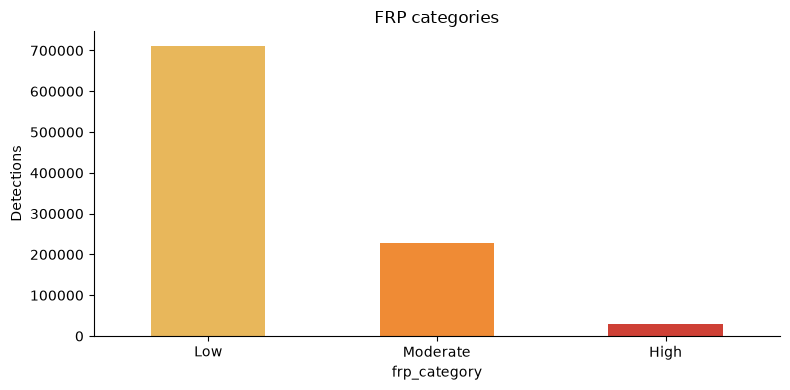

In [11]:
frp = clean['frp_category'].value_counts().reindex(['Low','Moderate','High']).fillna(0)
display(frp.rename('detections').to_frame())
frp.plot.bar(rot=0, color=['#e8b75b','#ef8b35','#ce4035'], title='FRP categories')
plt.ylabel('Detections')
plt.tight_layout()
plt.show()

### Day and night
We compare the number of observations and average FRP during day and night.

,detections,avg_frp
daynight,,
Day,644987,14.31
Night,323753,3.68


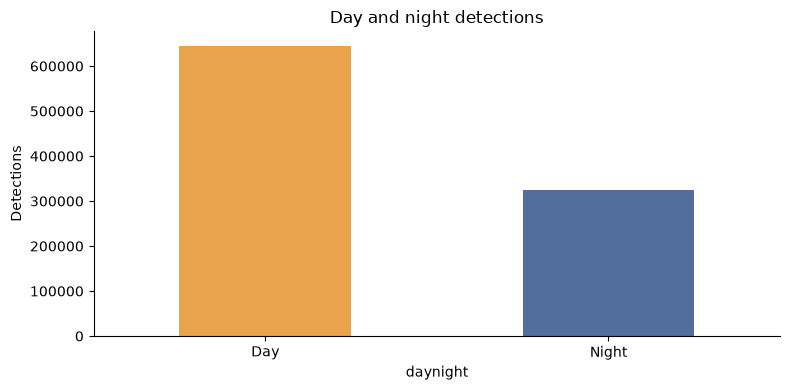

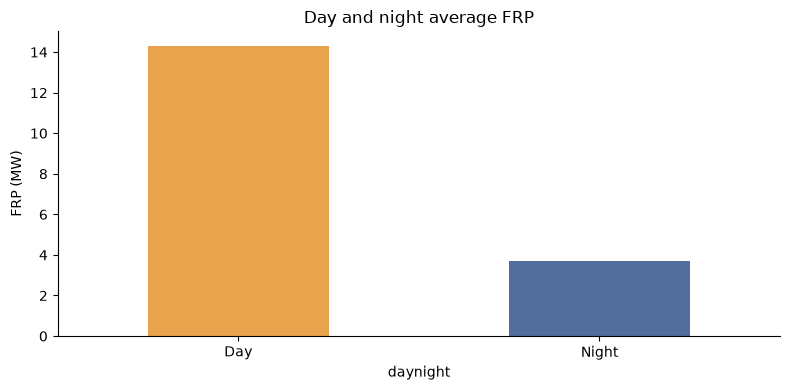

In [12]:
daynight = clean.groupby('daynight').agg(detections=('frp','size'), avg_frp=('frp','mean'))
daynight = daynight.rename(index={'D':'Day','N':'Night'})
display(daynight.round(2))
for col, title, unit in [('detections','Day and night detections','Detections'),
                         ('avg_frp','Day and night average FRP','FRP (MW)')]:
    daynight[col].plot.bar(rot=0, color=['#e9a34c','#526e9d'], title=title)
    plt.ylabel(unit)
    plt.tight_layout()
    plt.show()

### Detection confidence
NASA provides low, nominal and high detection confidence. This describes the satellite observation, not the severity of a fire.

,detections,avg_frp
confidence,,
High,76139,28.30
Low,87127,17.68
Nominal,805474,8.35


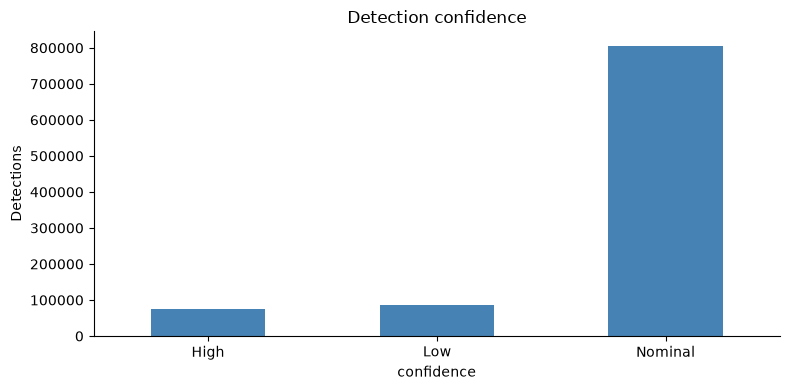

In [13]:
confidence = clean.groupby('confidence').agg(detections=('frp','size'), avg_frp=('frp','mean'))
confidence = confidence.rename(index={'l':'Low','n':'Nominal','h':'High'})
display(confidence.round(2))
confidence['detections'].plot.bar(rot=0, color='steelblue', title='Detection confidence')
plt.ylabel('Detections')
plt.tight_layout()
plt.show()

### Geographic hotspots
We count detections in each observed grid cell. In the plot, marker size shows count and color shows mean FRP.

Observed cells: 702


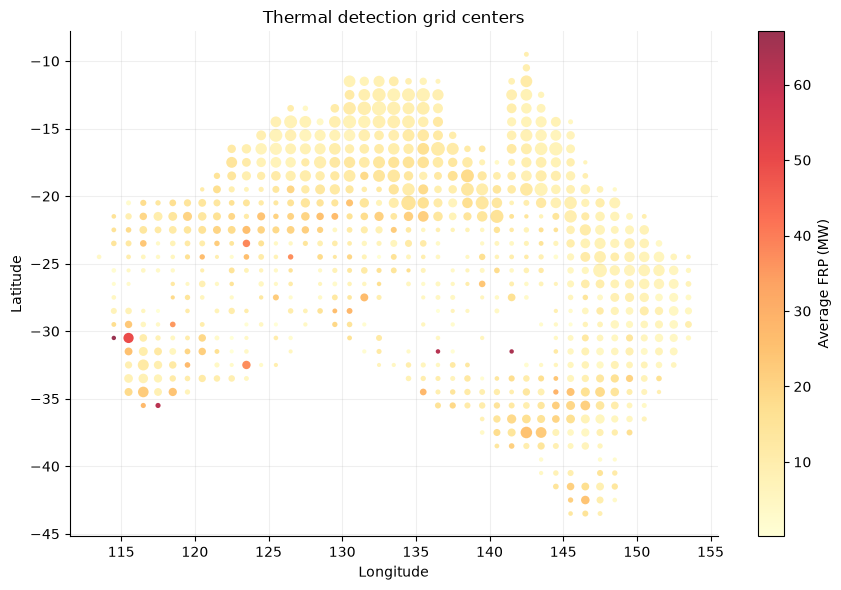

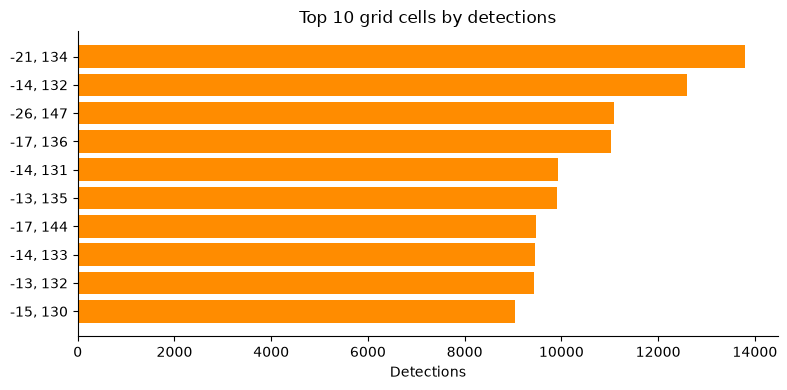

In [14]:
hotspots = pd.read_parquet(analytics / 'geographic_hotspots.parquet')
print('Observed cells:', len(hotspots))
plt.figure(figsize=(9, 6))
plt.scatter(hotspots['lon_grid'] + .5, hotspots['lat_grid'] + .5,
            s=8 + 100 * np.sqrt(hotspots['detections'] / hotspots['detections'].max()),
            c=hotspots['avg_frp'], cmap='YlOrRd', alpha=.8, edgecolors='none')
plt.colorbar(label='Average FRP (MW)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Thermal detection grid centers')
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()

top = hotspots.nlargest(10, 'detections').sort_values('detections')
labels = top['lat_grid'].astype(str) + ', ' + top['lon_grid'].astype(str)
plt.barh(labels, top['detections'], color='darkorange')
plt.title('Top 10 grid cells by detections')
plt.xlabel('Detections')
plt.tight_layout()
plt.show()

## 6. K-Means clustering
K-Means is unsupervised learning. We used latitude and longitude to group detections geographically with Spark MLlib. We selected k=4 using a sample comparison. Distances are measured in coordinate degrees, not actual geographic distance.

Selected k: 4
Full data silhouette: 0.6607248314778776


,cluster,detections,center_lat,center_lon,avg_frp
0,0,248750,-18.2049,142.4452,10.23
1,1,53567,-28.1221,118.7141,17.43
2,2,176415,-29.3597,148.0355,10.00
3,3,490008,-16.0576,131.4551,10.57


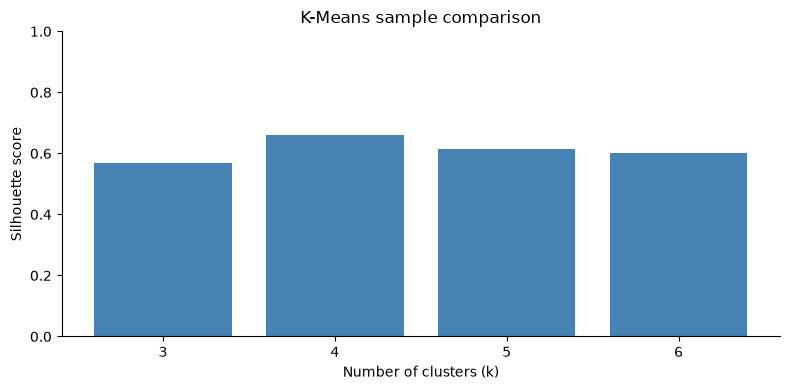

In [15]:
meta = json.loads((models / 'kmeans_metadata.json').read_text(encoding='utf-8-sig'))
clusters = pd.read_parquet(analytics / 'cluster_statistics.parquet').sort_values('cluster')
print('Selected k:', meta['k'])
print('Full data silhouette:', meta['silhouette_score'])
display(clusters)

# Recorded results from our original 10% sample experiment.
k_values = [3, 4, 5, 6]
silhouette = [.5685, .6615, .6155, .6001]
plt.bar([str(k) for k in k_values], silhouette, color='steelblue')
plt.title('K-Means sample comparison')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette score')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

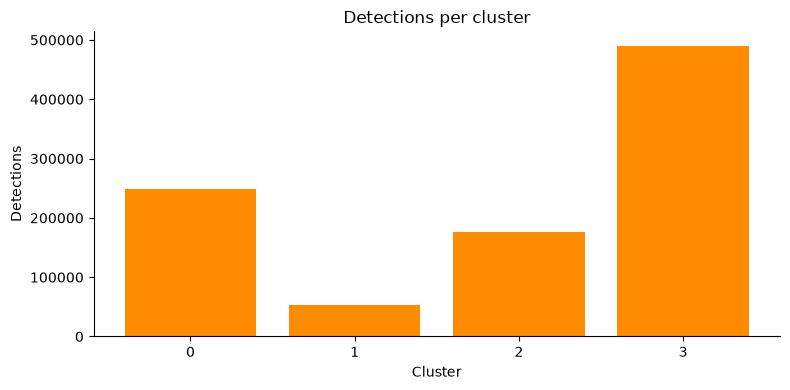

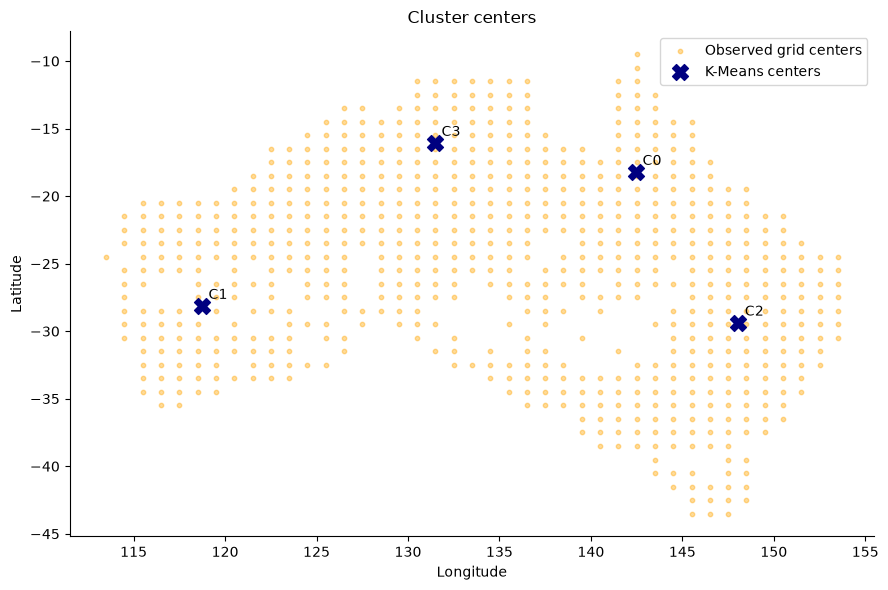

In [16]:
plt.bar(clusters['cluster'].astype(str), clusters['detections'], color='darkorange')
plt.title('Detections per cluster')
plt.xlabel('Cluster')
plt.ylabel('Detections')
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
plt.scatter(hotspots['lon_grid'] + .5, hotspots['lat_grid'] + .5,
            s=10, color='orange', alpha=.4, label='Observed grid centers')
plt.scatter(clusters['center_lon'], clusters['center_lat'], marker='X', s=130,
            color='navy', label='K-Means centers')
for row in clusters.itertuples():
    plt.annotate(f'C{row.cluster}', (row.center_lon, row.center_lat), xytext=(5, 5),
                 textcoords='offset points')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Cluster centers')
plt.legend()
plt.tight_layout()
plt.show()

### K-Means code
This is a small optional training example using the same features. The saved full-data results above are from the original training, not this sample.

In [17]:
# Change to True only if we want to train a demo during the discussion.
run_training = False
if run_training and spark is not None:
    from pyspark.ml.feature import VectorAssembler
    from pyspark.ml.clustering import KMeans
    from pyspark.ml.evaluation import ClusteringEvaluator

    sample = df.select('latitude', 'longitude').sample(False, .01, seed=42)
    vectors = VectorAssembler(inputCols=['latitude','longitude'], outputCol='features').transform(sample)
    km = KMeans(k=4, seed=42).fit(vectors)
    print('Sample silhouette:', ClusteringEvaluator().evaluate(km.transform(vectors)))
else:
    print('Using the original saved K-Means results.')

Using the original saved K-Means results.


## 7. Prediction dataset
For Random Forest we use a fixed grid of 822 cells based on Australia's land boundaries. Every cell has a record for each month, including months with zero detections.

The target is 1 if at least one thermal detection was recorded, otherwise 0. The features use only the previous three months' counts, location and target month. The current month's count is not an input.

Shape: (7398, 8)
Grid cells: 822
Features: ['lat_grid', 'lon_grid', 'month', 'lag_1', 'lag_2', 'lag_3']


,lat_grid,lon_grid,month,lag_1,lag_2,lag_3,target,detections
0,-55,158,4,0,0,0,0,0
1,-55,158,5,0,0,0,0,0
2,-55,158,6,0,0,0,0,0
3,-55,158,7,0,0,0,0,0
4,-55,158,8,0,0,0,0,0


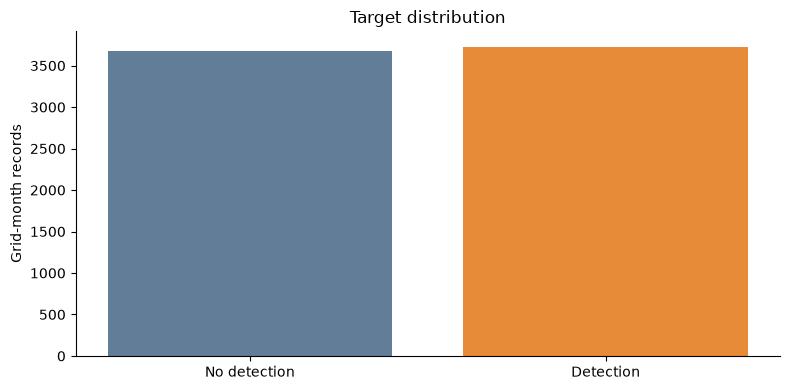

In [18]:
pred = pd.read_parquet(data / 'prediction_dataset.parquet')
features = ['lat_grid','lon_grid','month','lag_1','lag_2','lag_3']
print('Shape:', pred.shape)
print('Grid cells:', len(pred[['lat_grid','lon_grid']].drop_duplicates()))
print('Features:', features)
display(pred.head())

target_counts = pred['target'].value_counts().reindex([0,1], fill_value=0)
plt.bar(['No detection', 'Detection'], target_counts, color=['#627d98','#e88b38'])
plt.title('Target distribution')
plt.ylabel('Grid-month records')
plt.tight_layout()
plt.show()

### Train, validation and test
We split by time, not randomly. January to March supply the first three lag features. The test is rolling one-month-ahead: December uses known November observations.

,rows
Train Apr-Sep,4932
Validation Oct,822
Test Nov-Dec,1644


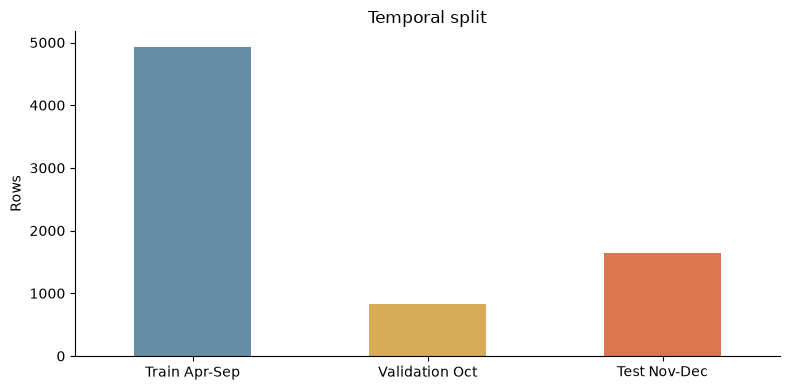

In [19]:
train = pred[pred['month'].between(4,9)]
validation = pred[pred['month'] == 10]
test = pred[pred['month'].between(11,12)]
split = pd.Series({'Train Apr-Sep':len(train), 'Validation Oct':len(validation), 'Test Nov-Dec':len(test)})
display(split.rename('rows').to_frame())
split.plot.bar(rot=0, color=['#658da6','#d7ab57','#d8774d'], title='Temporal split')
plt.ylabel('Rows')
plt.tight_layout()
plt.show()

## 8. Random Forest
Random Forest combines many decision trees. We trained a 100-tree classifier with Spark MLlib. The model uses the six features listed above.

The code below shows the training method. To keep Run All quick, we use the predictions exported from the saved model by default.

In [20]:
if run_training and spark is not None:
    from pyspark.ml.feature import VectorAssembler
    from pyspark.ml.classification import RandomForestClassifier

    prediction_df = spark.read.parquet(str(data / 'prediction_dataset.parquet'))
    vectors = VectorAssembler(inputCols=features, outputCol='features').transform(prediction_df)
    training = vectors.filter(F.col('month').between(4,9))
    rf_model = RandomForestClassifier(labelCol='target', featuresCol='features',
                                      numTrees=100, maxDepth=6, seed=42).fit(training)
    print('Demo trees:', rf_model.getNumTrees)
else:
    print('Using saved Random Forest predictions.')

Using saved Random Forest predictions.


### Model evaluation
The baseline predicts a detection if the previous month had any detections. We compare it with Random Forest on the same November–December test records.

Test rows: 1644


,Accuracy,Precision,Recall,F1
Random Forest,0.8139,0.8141,0.8438,0.8287
Baseline,0.7865,0.7798,0.8358,0.8068


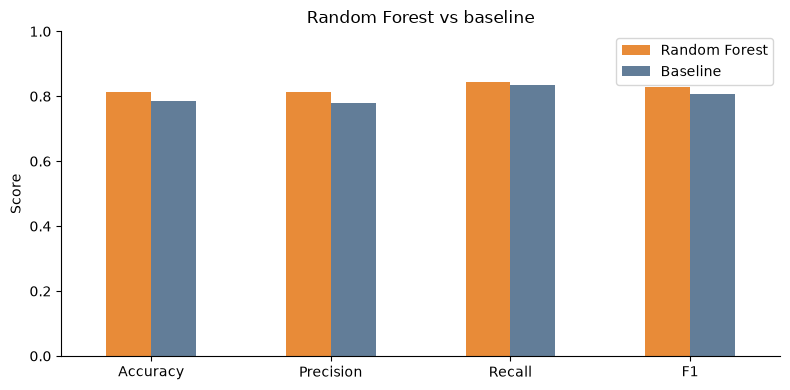

In [21]:
scores = pd.read_parquet(data / 'geographic_predictions_2024_test.parquet')
y = scores['actual_detection'].astype(int)
rf = scores['prediction'].astype(int)
baseline = (scores['previous_1_month_detections'] > 0).astype(int)
prob = scores['probability_detection'].astype(float)

def evaluate(guess):
    return {'Accuracy': accuracy_score(y, guess),
            'Precision': precision_score(y, guess, zero_division=0),
            'Recall': recall_score(y, guess, zero_division=0),
            'F1': f1_score(y, guess, zero_division=0)}

results = pd.DataFrame({'Random Forest': evaluate(rf), 'Baseline': evaluate(baseline)}).T
print('Test rows:', len(y))
display(results.round(4))
results.T.plot.bar(rot=0, color=['#e88b38','#627d98'], title='Random Forest vs baseline')
plt.ylim(0, 1)
plt.ylabel('Score')
plt.tight_layout()
plt.show()

### Confusion matrix
Rows are actual classes and columns are predicted classes. Class 1 means a detection was recorded.

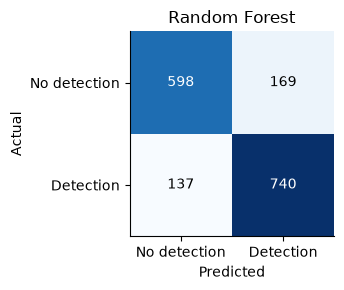

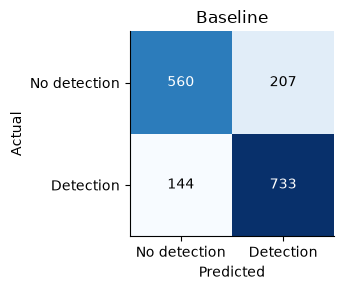

In [22]:
for name, guess in [('Random Forest', rf), ('Baseline', baseline)]:
    cm = confusion_matrix(y, guess, labels=[0,1])
    plt.figure(figsize=(4, 3))
    plt.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i,j], ha='center', va='center',
                     color='white' if cm[i,j] > cm.max()/2 else 'black')
    plt.xticks([0,1], ['No detection','Detection'])
    plt.yticks([0,1], ['No detection','Detection'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(name)
    plt.tight_layout()
    plt.show()

### ROC curve
ROC-AUC measures how well the model ranks positive cases above negative cases. Brier score measures squared error of the model scores (lower is better).

ROC-AUC: 0.8767
Brier score: 0.141


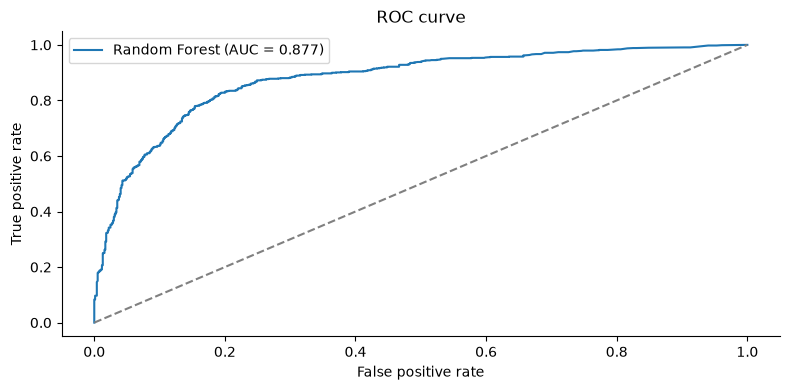

In [23]:
fpr, tpr, _ = roc_curve(y, prob)
auc = roc_auc_score(y, prob)
print('ROC-AUC:', round(auc, 4))
print('Brier score:', round(brier_score_loss(y, prob), 4))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {auc:.3f})')
plt.plot([0,1],[0,1], '--', color='gray')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve')
plt.legend()
plt.tight_layout()
plt.show()

### Feature importance
These are the feature importance values printed by our original Spark training run. The previous month's count was the most important feature.

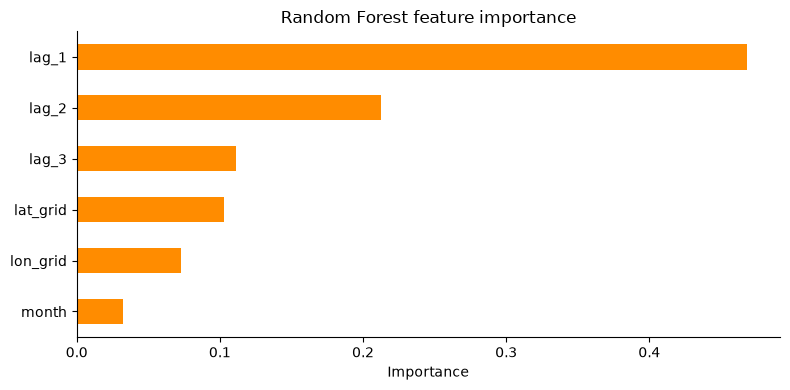

In [24]:
importance = pd.Series([.1028,.0731,.0322,.4679,.2129,.1112], index=features)
importance.sort_values().plot.barh(color='darkorange', title='Random Forest feature importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## 9. January 2025 prediction
We used October, November and December 2024 counts to score all 822 cells for January 2025. We did not compare these scores with actual January 2025 observations. January was not a training target month, so this is an experimental retrospective prediction, not a live forecast.

Grid cells: 822
Predicted detection: 447
Predicted no detection: 375


,lat_grid,lon_grid,month,previous_1_month_detections,previous_2_month_detections,previous_3_month_detections,actual_detection,actual_detections,prediction,probability_no_detection,probability_detection,forecast_year
0,-55,158,1,0.0,0.0,0.0,NaN,NaN,0,0.805898,0.194102,2025
1,-44,145,1,0.0,0.0,13.0,NaN,NaN,0,0.513793,0.486207,2025
2,-44,146,1,0.0,18.0,12.0,NaN,NaN,1,0.293876,0.706124,2025
3,-44,147,1,0.0,2.0,2.0,NaN,NaN,1,0.456817,0.543183,2025
4,-44,148,1,0.0,0.0,0.0,NaN,NaN,0,0.765496,0.234504,2025


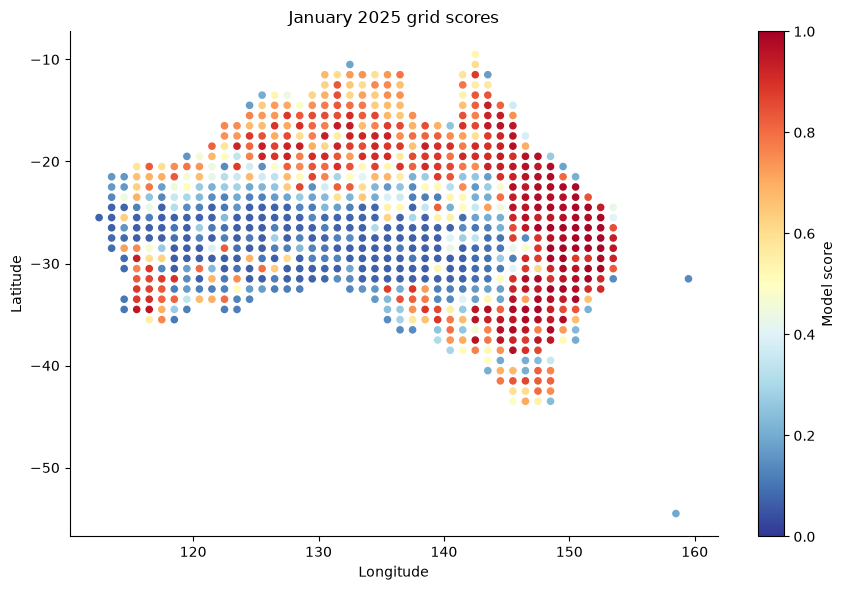

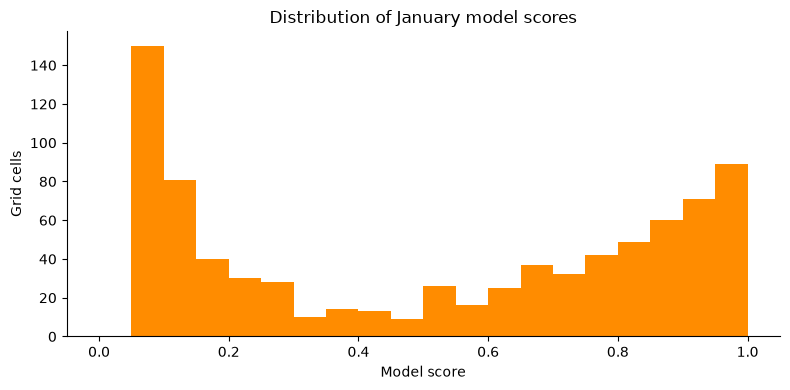

In [25]:
jan = pd.read_parquet(data / 'geographic_predictions_2025_01.parquet')
print('Grid cells:', len(jan))
print('Predicted detection:', (jan['prediction'] == 1).sum())
print('Predicted no detection:', (jan['prediction'] == 0).sum())
display(jan.head())

plt.figure(figsize=(9, 6))
plt.scatter(jan['lon_grid'] + .5, jan['lat_grid'] + .5,
            c=jan['probability_detection'], cmap='RdYlBu_r', vmin=0, vmax=1, s=20)
plt.colorbar(label='Model score')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('January 2025 grid scores')
plt.tight_layout()
plt.show()

plt.hist(jan['probability_detection'], bins=20, range=(0,1), color='darkorange')
plt.title('Distribution of January model scores')
plt.xlabel('Model score')
plt.ylabel('Grid cells')
plt.tight_layout()
plt.show()

## 10. Dashboard
[Open FireWatch AI](https://firewatch-ai-jarrkdvrjrbrrjcl9e2uv5.streamlit.app/)

- Overview: totals, map and monthly charts.
- Temporal Analytics: monthly trends, FRP and observation categories.
- Geographic Intelligence: grid map, minimum detection filter and cluster centers.
- ML Intelligence: K-Means results and silhouette score.
- Hotspot Prediction: historical test results, January scenario, grid selection and scores.
- Data Explorer: tables, sample data and CSV downloads.

The app reads saved Parquet and JSON files, so Spark is not needed on the web server. The maps have a 2D mode for browsers without WebGL2.

## 11. Conclusion
We processed nearly one million observations and used Spark filtering, aggregation, SQL and joins. October was the busiest month. We used K-Means for geographic clustering and Random Forest for monthly detection classification. The Random Forest performed better than the previous-month baseline in our 2024 test.

The dataset is manageable on one computer, but Spark gives us a processing pipeline that can be extended to more years and regions. We only have one year of data. The model scores are not calibrated fire probabilities, and no detection does not prove there was no fire.

In [26]:
if spark is not None:
    try:
        spark.stop()
    except Exception as e:
        print('Spark shutdown:', e)
print('Done.')

Done.
